# Ex08


Tự viết toàn bộ code. File này không có lời giải.

Làm lần lượt sáu phần:

1. Mã hóa (LabelEncoder và OneHotEncoder)
2. Ghép thành một bảng số duy nhất (concat)
3. Chuẩn hóa (StandardScaler hoặc MinMaxScaler)
4. Đưa bảng đã chuẩn hóa vào KMeans để gom cụm
5. Elbow để xem k
6. KNN để dự đoán Response

Dữ liệu: data/marketing_campaign.csv, dấu phân tách là tab.

Dùng đúng các cột sau, không thêm cột khác vào bảng đưa vào mô hình:

| Cột | Việc phải làm |
|---|---|
| Education | LabelEncoder |
| Marital_Status | OneHotEncoder |
| Income, Recency, MntWines, MntMeatProducts | giữ nguyên, vì đã là số |

Bỏ các dòng thiếu Income trước khi mã hóa. Không đưa Response vào bảng đặc trưng. Response chỉ dùng làm nhãn ở phần KNN.

random_state=0. Với KMeans đặt thêm n_init=10.


## 1. Mã hóa

Education và Marital_Status là chữ. KMeans không nhận chữ.

In classes_ của LabelEncoder sau khi fit. In tên cột do OneHotEncoder sinh ra.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

df = pd.read_csv('marketing_campaign.csv',sep='\t')



In [4]:
#ma hoa education
df = df.dropna(subset=['Income']).reset_index(drop=True)

le = LabelEncoder()
education_encoded = le.fit_transform(df['Education'])

print(' classes cua labelencoded: ')
print(le.classes_)

education_df = pd.DataFrame({'Education':education_encoded})
education_df.head()

 classes cua labelencoded: 
['2n Cycle' 'Basic' 'Graduation' 'Master' 'PhD']


,Education
0,2
1,2
2,2
3,2
4,4


In [5]:
#ma hoa marital_status
ohe = OneHotEncoder(sparse_output=False)
marital_oh = ohe.fit_transform(df[['Marital_Status']])
columns_oh = ohe.get_feature_names_out(['Marital_Status'])
print("Ten cot de onehotencode sinh ra: ")
print(columns_oh)

marital_df = pd.DataFrame(marital_oh,columns=columns_oh)

marital_df

Ten cot de onehotencode sinh ra: 
['Marital_Status_Absurd' 'Marital_Status_Alone' 'Marital_Status_Divorced'
 'Marital_Status_Married' 'Marital_Status_Single'
 'Marital_Status_Together' 'Marital_Status_Widow' 'Marital_Status_YOLO']


,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2211,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2212,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2213,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2214,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


**Trả lời, không cần code.**

1. LabelEncoder xếp Education theo thứ tự nào? Thứ tự đó có phải Basic, rồi 2n Cycle, Graduation, Master, PhD hay không?
2. Vì sao Marital_Status dùng OneHotEncoder còn Education lại dùng LabelEncoder trong bài này?


## 2. Ghép thành một bảng số duy nhất

Ghép ba khối theo cột: số của Education, các cột biến giả của Marital_Status, và bốn cột số. Kết quả là một DataFrame, mọi cột đều là số, số dòng bằng số dòng sau khi bỏ Income thiếu.

In shape và columns.


In [6]:
numeric_df = df[['Income', 'Recency', 'MntWines', 'MntMeatProducts']]
X = pd.concat([education_df,marital_df,numeric_df],axis=1)
X


,Education,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO,Income,Recency,MntWines,MntMeatProducts
0,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,58138.0,58,635,546
1,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,46344.0,38,11,6
2,2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,71613.0,26,426,127
3,2,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,26646.0,26,11,20
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,58293.0,94,173,118
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2211,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,61223.0,46,709,182
2212,4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,64014.0,56,406,30
2213,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,56981.0,91,908,217
2214,3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,69245.0,8,428,214


In [7]:
print(X.shape)
columns_oh.tolist()

(2216, 13)


['Marital_Status_Absurd',
 'Marital_Status_Alone',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Single',
 'Marital_Status_Together',
 'Marital_Status_Widow',
 'Marital_Status_YOLO']

**Trả lời.**

3. Bảng ghép có bao nhiêu dòng, bao nhiêu cột? Kể tên các cột biến giả.
- Co 2240 dong va 41 cot, cac cot bien gia: 
 'Marital_Status_Absurd',
 'Marital_Status_Alone',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Single',
 'Marital_Status_Together',
 'Marital_Status_Widow',
 'Marital_Status_YOLO'

## 3. Chuẩn hóa

Chọn một trong hai: StandardScaler hoặc MinMaxScaler. Fit trên toàn bộ bảng vừa ghép. In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số.


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled,columns=X.columns)
X_scaled.mean()


Education                  1.282568e-16
Marital_Status_Absurd     -3.206420e-18
Marital_Status_Alone       1.923852e-17
Marital_Status_Divorced   -4.008025e-17
Marital_Status_Married    -9.619261e-18
Marital_Status_Single     -3.046099e-17
Marital_Status_Together   -7.214446e-18
Marital_Status_Widow       9.619261e-18
Marital_Status_YOLO        9.619261e-18
Income                     5.210433e-17
Recency                   -2.404815e-18
MntWines                  -3.366741e-17
MntMeatProducts           -5.771557e-17
dtype: float64

**Trả lời.**

4. Bạn chọn scaler nào? Income và MntWines sẽ chi phối khoảng cách thế nào nếu bỏ bước này?
- Em chon Standard, neu bo buoc nay, income va mntwines co gia tri rat lon, de chi phoi khoang cach, vi vay neu dap dung kmean va knn thi cac khoang gia tri nho se khong dong gop nhieu.

## 4. K-Means

n_clusters=3. In số dòng mỗi cụm và trung bình Income, Recency, MntWines, MntMeatProducts theo cụm. Trung bình tính trên giá trị gốc, không tính trên bảng đã scale.


In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)


result = df[['Income', 'Recency', 'MntWines', 'MntMeatProducts']]
result['Cluster'] = clusters

print("Số dòng mỗi cụm:")
print(result.groupby('Cluster').size())

print("Trung bình các cột theo cụm:")
print(result.groupby('Cluster')[['Income', 'Recency', 'MntWines', 'MntMeatProducts']].mean().round(3))

Số dòng mỗi cụm:
Cluster
0    473
1    935
2    808
dtype: int64
Trung bình các cột theo cụm:
            Income  Recency  MntWines  MntMeatProducts
Cluster                                               
0        50984.512   49.004   291.461          184.279
1        52155.760   48.360   305.443          163.206
2        53092.325   49.772   312.665          161.264


C:\Users\tai33\AppData\Local\Temp\ipykernel_27472\2294255868.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['Cluster'] = clusters


**Trả lời.**

5. Ba cụm khác nhau ở mức chi tiêu nào? Gọi tên mỗi cụm bằng chữ, không bằng id 0, 1, 2.
Dựa vào trung bình MntWines và MntMeatProducts của từng cụm để gọi tên:
- Nhóm chi tiêu thấp: mức chi tiêu trung bình thấp.
- Nhóm chi tiêu trung bình: mức chi tiêu nằm giữa hai nhóm còn lại.
- Nhóm chi tiêu cao: mức chi tiêu trung bình cao.
6. Đổi random_state thì id cụm có thể đảo. Cách đọc ở câu 5 còn đúng không?
Cách đọc ở câu 5 vẫn đúng vì tên nhóm được đặt theo mức chi tiêu thực tế, không theo id cụm. Khi id đảo, nhóm chi tiêu thấp vẫn được gọi là “chi tiêu thấp”, tương tự với nhóm trung bình và cao.


## 5. Elbow

Dùng đúng bảng đã chuẩn hóa ở phần 3. Thử k từ 1 đến 8. Với mỗi k, lưu inertia. Vẽ inertia theo k, trục hoành là k, trục tung là inertia.


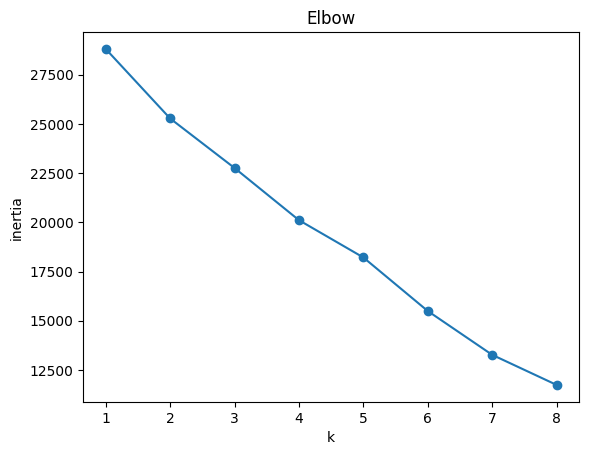

In [10]:

k_values = range(1, 9)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)


plt.plot(k_values, inertias, marker='o')
plt.xticks(k_values)
plt.xlabel('k')
plt.ylabel('inertia')
plt.title('Elbow')
plt.show()

**Trả lời.**

7. Inertia nhỏ nhất trong bảng nằm ở k nào? Vì sao không chọn k đó làm số cụm?
Inertia nhỏ nhất tại k = 8. Không chọn chỉ vì inertia nhỏ nhất, vì tăng số cụm thường làm inertia giảm
8. Nhìn chỗ đường gãy, bạn chọn k nào cho phòng marketing? Có trùng k = 3 ở phần 4 không?
Em chon k = 3, vi doi voi em lua chon nay giup phong marketing de dang phan nhom va quan ly hon, k=4 co ve thoai hon so voi doan dau nhung chiia qua nhieu cum nhu vay em nghi se kho quan ly hon.

## 6. KNN

KNN không gom cụm. KNN cần nhãn. Nhãn là Response. Bảng đặc trưng là bảng đã ghép ở phần 2, bản chưa chuẩn hóa.

Chia train/test, test_size=0.2, random_state=0, stratify theo Response.

Tạo một scaler mới, cùng loại với phần 3. Fit scaler chỉ trên tập train, rồi transform tập test. Không dùng lại scaler đã fit trên toàn bộ dữ liệu ở phần 3.

Thử n_neighbors trong 1, 3, 5, 7, 11, 21. Với mỗi k in accuracy và F1 của lớp 1. Chọn một k và in classification_report của k đó.


In [13]:

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report


y = df['Response']


X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

knn_scaler = StandardScaler()

X_train_scaled = knn_scaler.fit_transform(X_train)
X_test_scaled = knn_scaler.transform(X_test)


k_values = [1, 3, 5, 7, 11, 21]
results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    results.append({
        'k': k,
        'Accuracy': accuracy,
        'F1_class_1': f1
    })

results_df = pd.DataFrame(results)

print("Kết quả từng k:")
print(results_df.round(3).to_string(index=False))


best_k = int(
    results_df.loc[results_df['F1_class_1'].idxmax(), 'k']
)

print("k được chọn:", best_k)


best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)

best_pred = best_knn.predict(X_test_scaled)

print("\nClassification report:")
print(classification_report(y_test,best_pred,digits=3,zero_division=0))

Kết quả từng k:
 k  Accuracy  F1_class_1
 1     0.827       0.374
 3     0.840       0.324
 5     0.863       0.330
 7     0.869       0.341
11     0.867       0.306
21     0.858       0.160
k được chọn: 1

Classification report:
              precision    recall  f1-score   support

           0      0.887     0.912     0.899       377
           1      0.411     0.343     0.374        67

    accuracy                          0.827       444
   macro avg      0.649     0.628     0.637       444
weighted avg      0.815     0.827     0.820       444



**Trả lời.**

9. stratify theo Response giữ điều gì giữa train và test?
stratify=y giữ tỷ lệ Response = 0 và Response = 1 gần giống nhau giữa tập train và test.
10. Fit scaler trên cả bảng rồi mới chia train/test thì sai ở đâu?
Fit scaler trên cả bảng làm thông tin của tập test tham gia tính trung bình và độ lệch chuẩn. Đây là rò rỉ dữ liệu. Phải fit scaler chỉ trên train, rồi dùng scaler đó transform test.
11. k bạn chọn là bao nhiêu? Accuracy cao hơn F1 lớp 1 thì đọc thêm chỉ số nào trước khi kết luận mô hình tốt?
Em chọn k = 1 vì có F1 lớp 1 cao nhất: 0,374 trong các k đã thử.

Accuracy đạt 82,7%, nhưng cần xem thêm:
- Recall lớp 1 = 34,3%: chỉ phát hiện được khoảng 34 trong 100 khách thực sự có Response = 1, bỏ sót khoảng 66 khách.
- Precision lớp 1 = 41,1%: trong 100 khách được dự đoán là Response = 1, chỉ khoảng 41 khách đúng.
Vì lớp 0 chiếm 377/444 khách, Accuracy cao chưa đủ để kết luận mô hình tốt. Mô hình còn nhận diện lớp 1 khá yếu.
